In [1]:
import joblib # for saving the model
import sys # for checking what environment user is working in
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# model selections
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
import umap
from imblearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

In [2]:
from pathlib import Path
DATA_PATH = Path.home() / 'Downloads' / 'aug_data_v1/aug_data_v1'

print("Dataset path:", DATA_PATH)
print("Dataset folder exists:", DATA_PATH.exists())

Dataset path: /home/enby/Downloads/aug_data_v1/aug_data_v1
Dataset folder exists: True


In [24]:
from pathlib import Path
import cv2
import pandas as pd

root = DATA_PATH

train_rows = []
val_rows = []
test_rows = []

for class_dir in root.iterdir():

    if not class_dir.is_dir():
        continue

    class_name = class_dir.name

    for split in ["train", "validation", "test"]:

        split_dir = class_dir / split

        for file_path in split_dir.glob("*"):

            img = cv2.imread(
                str(file_path),
                cv2.IMREAD_GRAYSCALE
            )

            file_name = file_path.name

            row = {
                "class_name": class_name,
                "file_name": file_name,
                "path": str(file_path)
            }

            if split == "train":
                train_rows.append(row)

            elif split == "validation":
                val_rows.append(row)

            else:
                test_rows.append(row)

train_df = pd.DataFrame(train_rows)
val_df = pd.DataFrame(val_rows)
test_df = pd.DataFrame(test_rows)

In [25]:
X_train = train_df["path"]
y_train = train_df["class_name"]

X_val = val_df["path"]
y_val = val_df["class_name"]

X_test = test_df["path"]
y_test = test_df["class_name"]

In [26]:
# This is where the Eigenface augmentation gets done.
### Eigernfaces is basically PCA for image data
### We define the function here:

In [44]:
class Eigenfaces:
    def __init__(self,
                 X_train, X_test, X_val, y_train, y_test, y_val,
                 img_size):
        # All the objets we will re-use
        self.X_train, self.X_test, self.X_val, self.y_train, self.y_test, self.y_val = X_train, X_test, X_val, y_train, y_test, y_val
        
        self.img_size=img_size
        
        self.VECTOR_SIZE = self.img_size * self.img_size # size of the eigenface we want to create

        self.mean_face = None
        self.eigenfaces = None

        # encode labels for UMAP's plotting
        self.label_encoder = LabelEncoder()
        self.y_train_numeric = self.label_encoder.fit_transform(y_train)
        self.y_test_numeric = self.label_encoder.transform(y_test)
        self.y_val_numeric = self.label_encoder.transform(y_val)

    def data_matrix_creation(self, data): # tries to create resized images in preparation for the principle component analysis
        data_matrix = np.zeros(
            (len(data), self.VECTOR_SIZE)
        )
        for idx, path in enumerate(data):
            img = cv2.imread(
                path,
                cv2.IMREAD_GRAYSCALE
            )
            if img is None:
                continue
            resized = cv2.resize(
                img,
                (self.img_size, self.img_size)
            )
            
            resized = resized.astype(np.float32) / 255.0
            
            data_matrix[idx] = resized.flatten()
            
        return data_matrix
            
    def PCA(self, n_components=100): # Does PCA-Eigenface math on train data.
        data_matrix = self.data_matrix_creation(
            self.X_train
        )

        # calculate the avg face
        self.mean_face = np.mean(
            data_matrix,
            axis=0
        )
    
        # mean-center of the dataset
        centered = (
            data_matrix - self.mean_face
        )
    
        # computing the PCA using SVD
        print("Computing SVD to create the basis space...")
        U, self.S, Vt = np.linalg.svd(
            centered,
            full_matrices=False
        )
    
        # Save top k faces
        self.eigenfaces = Vt[:n_components]
    
        # Projections
        self.X_train_proj = (
            centered @ self.eigenfaces.T
        )

        self.pca_df = pd.DataFrame(
            self.X_train_proj[:, :2],
            columns=["PC1", "PC2"]
        )
        self.pca_df["Emotion"] = self.y_train.values
        print("Done!")
        
        return self.X_train_proj


    def Transform(self, data):
        if data == "X_test":
            matrix = self.data_matrix_creation(self.X_test)
    
            centered = matrix - self.mean_face
            self.X_test_proj = centered @ self.eigenfaces.T
            return self.X_test_proj
    
        elif data == "X_val":
            matrix = self.data_matrix_creation(self.X_val)
    
            centered = matrix - self.mean_face
            self.X_val_proj = centered @ self.eigenfaces.T
            return self.X_val_proj

    def PlotEigenfaces(self, n_faces=None, 
                       array=False, scatter=False, scree=False
                      ): # plotting everything
        
        if n_faces is None:
            n_faces=6
        if array is True: # prints the eigenfaces for cool visual
            if self.eigenfaces is None:
                raise ValueError(
                    "Run PCA() before plotting eigenfaces."
                )
        
            fig, axes = plt.subplots(
                2,
                (n_faces + 1) // 2,
                figsize=(12, 6)
            )
        
            axes = np.array(axes).flatten()
        
            for i in range(min(n_faces, len(self.eigenfaces))):
                eigenface = self.eigenfaces[i].reshape(
                    self.img_size,
                    self.img_size
                )
        
                eigenface = cv2.normalize(
                    eigenface,
                    None,
                    0,
                    255,
                    cv2.NORM_MINMAX
                )
        
                axes[i].imshow(
                    eigenface,
                    cmap="gray"
                )
        
                axes[i].set_title(
                    f"Eigenface {i+1}"
                )
        
                axes[i].axis("off")
            plt.suptitle(f"Top {n_faces} Facial Variance")
            plt.tight_layout()
        
            plt.show()
            
        if scatter is True: # uses UMAP to describe the data
            UMAP = umap.UMAP(n_components=3)
            X_train_umap = UMAP.fit_transform(self.X_train_proj, y=self.y_train_numeric)
            X_test_umap = UMAP.transform(self.X_test_proj)

            unique_labels = np.unique(self.y_train)

            if not hasattr(self, "X_test_proj"):
                raise ValueError(
                    "Run Transform('X_test') before plotting."
                )
            color_list = ['#CC79A7', '#E69F00', '#0072B2'] # Match the alphabetical order of your labels

            sns.scatterplot(
                x=X_train_umap[:,0],
                y=X_train_umap[:,1],
                hue=self.y_train.squeeze(),
                palette=dict(zip(unique_labels, color_list)),
                alpha=0.7
            )
            plt.title("UMAP Projection of PCA-transformed Features")
            plt.xlabel("UMAP Dim 1");plt.ylabel("UMAP Dim 2");
            plt.show()

        if scree is True: # Does math for scree plot, and plots screeeeeeeeeeee
            exp_var = (
                self.S**2 /
                np.sum(self.S**2)
            )
        
            cum_var = np.cumsum(exp_var)
        
            num_components = len(exp_var)

            optimal_k = np.argmax(cum_var >= .9) + 1
        
            fig, ax1 = plt.subplots(
                figsize=(12, 6)
            )
        
            ax1.bar(
                range(1, num_components + 1),
                exp_var,
                alpha=0.6,
                color="steelblue",
                label="Individual Variance"
            )
        
            ax1.set_xlabel(
                "Principal Component"
            )
        
            ax1.set_ylabel(
                "Explained Variance Ratio",
                color="steelblue"
            )
        
            ax1.tick_params(
                axis="y",
                labelcolor="steelblue"
            )
        
            ax2 = ax1.twinx()
        
            ax2.plot(
                range(1, num_components + 1),
                cum_var,
                color="darkorange",
                marker="o",
                linewidth=2,
                label="Cumulative Variance"
            )
        
            ax2.set_ylabel(
                "Cumulative Variance",
                color="darkorange"
            )
        
            ax2.tick_params(
                axis="y",
                labelcolor="darkorange"
            )

            # Horizontal Threshold
            ax2.axhline(
                y=0.90,
                color="red",
                linestyle="--",
                alpha=0.7,
                label="90% Threshold"
            )
            
            # Vertical Threshold
            ax2.axvline(
                x=optimal_k,
                color="red",
                linestyle=":",
                linewidth=2,
                label=f"{optimal_k -1}"
            )

            # single point
            ax2.scatter(
                optimal_k,
                cum_var[optimal_k - 1],
                color='green',
                s=100,
                zorder=5
            )
            ax2.annotate(
                f'k={optimal_k}\n{cum_var[optimal_k-1]:.1%}',
                xy=(optimal_k,
                    cum_var[optimal_k-1]),
                xytext=(optimal_k+5,
                        cum_var[optimal_k-1]-0.1),
                arrowprops=dict(
                    arrowstyle='->',
                    color='green'
                )
            )
            lines1, labels1 = ax1.get_legend_handles_labels()
        
            lines2, labels2 = ax2.get_legend_handles_labels()
        
            ax1.legend(
                lines1 + lines2,
                labels1 + labels2,
                loc="center right"
            )
        
            plt.title(
                "Eigenfaces Scree Plot"
            )
        
            plt.tight_layout()
        
            plt.show()

### Note, for image size, start with `img_size=48` and increase by factorization (eg. +1, +2, +3, +4, +6, +12, +16, +24, +48) 
#### Why? This takes a lot of CPU power (opimization problem)

In [64]:
Eigen = Eigenfaces(
    X_train, X_test, X_val,
    y_train, y_test, y_val,
    img_size=48
)

X_train_proj = Eigen.PCA(
    n_components=75
)
X_test_proj = Eigen.Transform("X_test")
X_val_proj = Eigen.Transform("X_val")

Computing SVD to create the basis space...
Done!


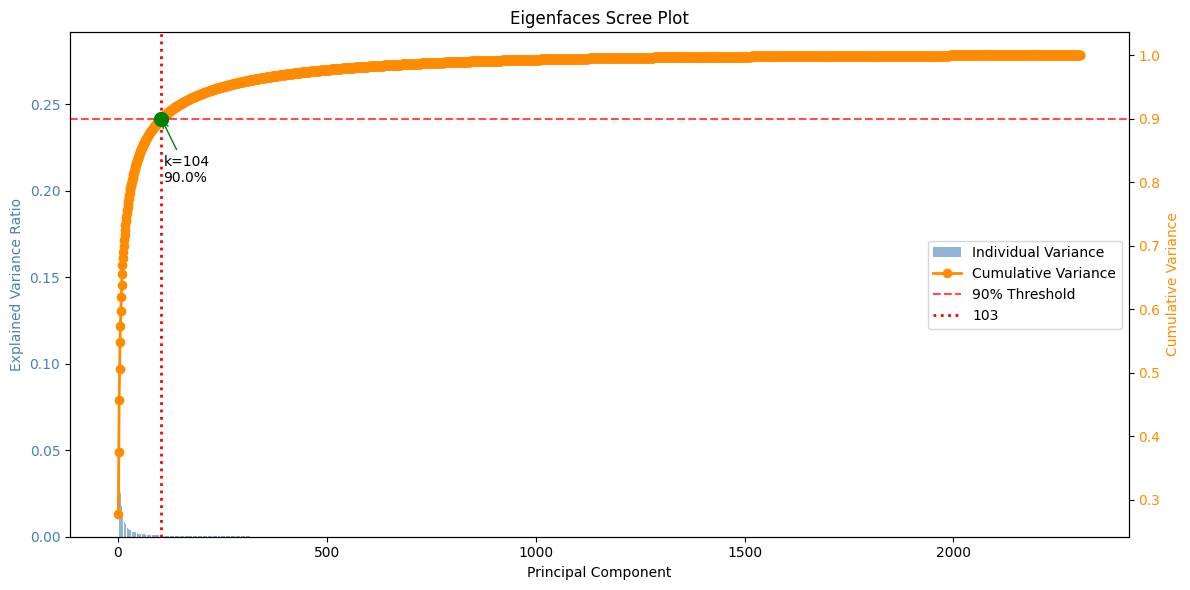

In [65]:
Eigen.PlotEigenfaces(scree=True)

### optimal k shows `70` so we run the PCA again with k being a fixed number for `n_components`

In [66]:
Eigen = Eigenfaces(
    X_train, X_test, X_val,
    y_train, y_test, y_val,
    img_size=48
)

X_train_proj = Eigen.PCA(
    n_components=104
)
X_test_proj = Eigen.Transform("X_test")
X_val_proj = Eigen.Transform("X_val")

Computing SVD to create the basis space...
Done!


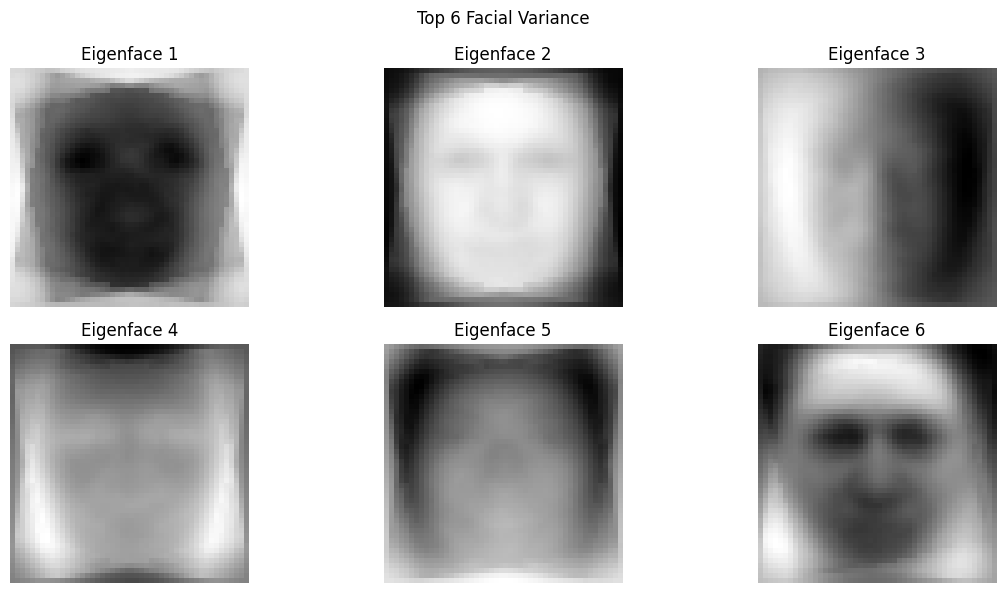

In [67]:
Eigen.PlotEigenfaces(array=True)

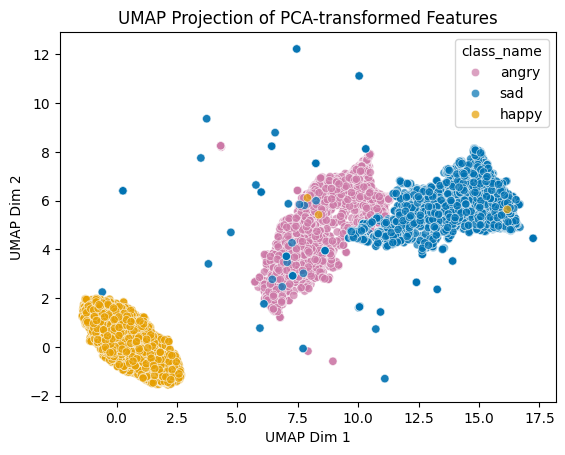

In [68]:
Eigen.PlotEigenfaces(scatter=True)

In [81]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score
)
from itertools import product

results = []

depths = [25, 50, 100, None]
n_estimators = [50, 100]
criteria = ["gini", "entropy", "log_loss"]
#min_splits = [5, 10, None]

for depth, n_est, criterion in product(
    depths,
    n_estimators,
    criteria,
    #min_splits
):

    pipe = Pipeline([
        ('classifier',
         RandomForestClassifier(
             max_depth=depth,
             n_estimators=n_est,
             criterion=criterion,
             #min_samples_split=min_split,
             random_state=42
         ))
    ])

    pipe.fit(
        X_train_proj,
        y_train
    )

    val_pred = pipe.predict(
        X_val_proj
    )

    accuracy = accuracy_score(
        y_val,
        val_pred
    )

    macro_f1 = f1_score(
        y_val,
        val_pred,
        average="macro"
    )

    results.append({
        "max_depth": depth,
        "n_estimators": n_est,
        "criterion": criterion,
        #"min_samples_split": min_split,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    print(
        f"Depth={depth}, "
        f"Trees={n_est}, "
        f"Criterion={criterion}, "
        #f"MinSplit={min_split}, "
        f"Accuracy={accuracy:.4f}, "
        f"MacroF1={macro_f1:.4f}"
    )

results_df = (
    pd.DataFrame(results)
    .sort_values("macro_f1", ascending=False)
)

print("\nTop 10 Models")
print(results_df.head(10))

Depth=25, Trees=50, Criterion=gini, MinSplit=5, Accuracy=0.6498, MacroF1=0.4946
Depth=25, Trees=50, Criterion=gini, MinSplit=10, Accuracy=0.6498, MacroF1=0.5002
Depth=25, Trees=50, Criterion=entropy, MinSplit=5, Accuracy=0.6402, MacroF1=0.4803
Depth=25, Trees=50, Criterion=entropy, MinSplit=10, Accuracy=0.6456, MacroF1=0.4831
Depth=25, Trees=100, Criterion=gini, MinSplit=5, Accuracy=0.6606, MacroF1=0.5053
Depth=25, Trees=100, Criterion=gini, MinSplit=10, Accuracy=0.6594, MacroF1=0.5032
Depth=25, Trees=100, Criterion=entropy, MinSplit=5, Accuracy=0.6576, MacroF1=0.4888
Depth=25, Trees=100, Criterion=entropy, MinSplit=10, Accuracy=0.6721, MacroF1=0.5066
Depth=50, Trees=50, Criterion=gini, MinSplit=5, Accuracy=0.6390, MacroF1=0.4860
Depth=50, Trees=50, Criterion=gini, MinSplit=10, Accuracy=0.6312, MacroF1=0.4746
Depth=50, Trees=50, Criterion=entropy, MinSplit=5, Accuracy=0.6384, MacroF1=0.4800
Depth=50, Trees=50, Criterion=entropy, MinSplit=10, Accuracy=0.6426, MacroF1=0.4795
Depth=50, Tr

In [82]:
best_params_rf = results_df.iloc[0]

print(best_params)

n_neighbors    5.000000
min_dist       0.000000
score          0.565584
accuracy       0.670277
macro_f1       0.500133
Name: 0, dtype: float64


In [88]:
best_rf = RandomForestClassifier(
    max_depth=int(best_params_rf["max_depth"]),
    n_estimators=int(best_params_rf["n_estimators"]),
    criterion=best_params_rf["criterion"],
   # min_samples_split=int(best_params_rf["min_samples_split"]),
    random_state=42
)

# Final model evaluation
X_trainval = np.vstack([X_train_proj, X_val_proj])
y_trainval = np.concatenate([y_train, y_val])
best_rf.fit(
    X_trainval,
    y_trainval
)

test_pred = best_rf.predict(
    X_test_proj
)

print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Angry", "Happy", "Sad"]
    )
)

              precision    recall  f1-score   support

       Angry       0.61      0.38      0.47       463
       Happy       0.72      0.92      0.81      1029
         Sad       0.35      0.15      0.21       181

    accuracy                           0.68      1673
   macro avg       0.56      0.48      0.50      1673
weighted avg       0.65      0.68      0.65      1673



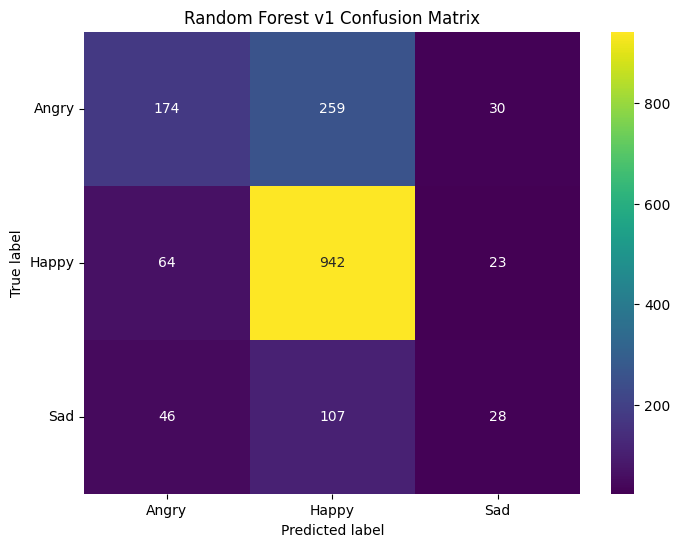

In [89]:
# use seaborn and matplotlib to plot
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ['Angry', 'Happy', 'Sad']

plt.figure(figsize=(8,6))
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(
cm,
annot=True,
fmt='d',
cmap='viridis',
xticklabels=class_names,
yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.yticks(rotation=360)
plt.title("Random Forest v1 Confusion Matrix")
plt.savefig("Conf_Matrix_Eigen_v1.png")
plt.show()

In [90]:
# save the model with joblib
joblib.dump(pipe, 'random_forest_eigen_v1.joblib')

['random_forest_eigen_v1.joblib']

# Using UMAP to test model accuracy

In [91]:
from sklearn.preprocessing import LabelEncoder
from itertools import product
# encode labels first
label_encoder = LabelEncoder()
y_train_numeric = label_encoder.fit_transform(y_train)
y_test_numeric = label_encoder.transform(y_test)
y_val_numeric = label_encoder.transform(y_val)

results = []

for n_neighbors, min_dist in product(
    [5, 15, 30, 50],
    [0.0, 0.1, 0.25, 0.5]
):

    reducer = umap.UMAP(
        n_components=10,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        random_state=42
    )

    X_train_umap = reducer.fit_transform(
        X_train_proj,
        y_train_numeric
    )

    X_val_umap = reducer.transform(
        X_val_proj
    )

    rf = RandomForestClassifier(
        random_state=42
    )

    rf.fit(
        X_train_umap,
        y_train
    )

    score = rf.score(
        X_val_umap,
        y_val
    )
    accuracy = accuracy_score(
        y_val,
        val_pred
    )

    macro_f1 = f1_score(
        y_val,
        val_pred,
        average="macro"
    )

    print(
        #f"Depth={depth}, "
        f"Neighbors={n_neighbors}",
        f"Min Dist={min_dist}",
        #f"Trees={n_est}, "
        #f"Criterion={criterion}, "
        #f"MinSplit={min_split}, "
        f"Accuracy={accuracy:.4f}, "
        f"MacroF1={macro_f1:.4f}"
    )
    results.append({
        "n_neighbors": n_neighbors,
        "min_dist": min_dist,
        "score": score,
        "accuracy": accuracy,
        "macro_f1": macro_f1
    })

    results_df = (
        pd.DataFrame(results)
        .sort_values("macro_f1", ascending=False)
    )

print("\nTop 10 Models")
print(results_df.head(10))

/home/enby/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Neighbors=5 Min Dist=0.0 Accuracy=0.6703, MacroF1=0.5001


/home/enby/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Neighbors=5 Min Dist=0.1 Accuracy=0.6703, MacroF1=0.5001


/home/enby/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Neighbors=5 Min Dist=0.25 Accuracy=0.6703, MacroF1=0.5001


... (22 outputs left out)

/home/enby/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Neighbors=50 Min Dist=0.25 Accuracy=0.6703, MacroF1=0.5001


/home/enby/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Neighbors=50 Min Dist=0.5 Accuracy=0.6703, MacroF1=0.5001

Top 10 Models
   n_neighbors  min_dist     score  accuracy  macro_f1
0            5      0.00  0.565584  0.670277  0.500133
1            5      0.10  0.567990  0.670277  0.500133
2            5      0.25  0.554753  0.670277  0.500133
3            5      0.50  0.571600  0.670277  0.500133
4           15      0.00  0.536703  0.670277  0.500133
5           15      0.10  0.548135  0.670277  0.500133
6           15      0.25  0.566787  0.670277  0.500133
7           15      0.50  0.593863  0.670277  0.500133
8           30      0.00  0.552347  0.670277  0.500133
9           30      0.10  0.561974  0.670277  0.500133


In [92]:
best_params_umap = results_df.iloc[0]

print(best_params_umap)

n_neighbors    5.000000
min_dist       0.000000
score          0.565584
accuracy       0.670277
macro_f1       0.500133
Name: 0, dtype: float64


In [95]:
best_umap = umap.UMAP(
        n_components=10,
        n_neighbors=int(best_params_umap["n_neighbors"]),
        min_dist=best_params_umap["min_dist"],
        random_state=42
    )


X_trainval = np.vstack([X_train_proj, X_val_proj])
y_trainval = np.concatenate([y_train, y_val])
y_trainval_numeric = label_encoder.transform(
    y_trainval
)


X_train_umap = best_umap.fit_transform(
        X_trainval,
        y_trainval_numeric
    )

X_test_umap = best_umap.transform(
        X_test_proj
    )

best_rf = RandomForestClassifier(
    max_depth=int(best_params_rf["max_depth"]),
    n_estimators=best_params_rf["n_estimators"],
    criterion=best_params_rf["criterion"],
    min_samples_split=best_params_rf["min_samples_split"],
    random_state=42
)


best_rf.fit(
    X_train_umap,
    y_trainval
)

test_pred = best_rf.predict(
    X_test_umap
)

print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Angry", "Happy", "Sad"]
    )
)

/home/enby/.local/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


              precision    recall  f1-score   support

       Angry       0.44      0.35      0.39       463
       Happy       0.70      0.73      0.71      1029
         Sad       0.19      0.24      0.21       181

    accuracy                           0.57      1673
   macro avg       0.44      0.44      0.44      1673
weighted avg       0.57      0.57      0.57      1673



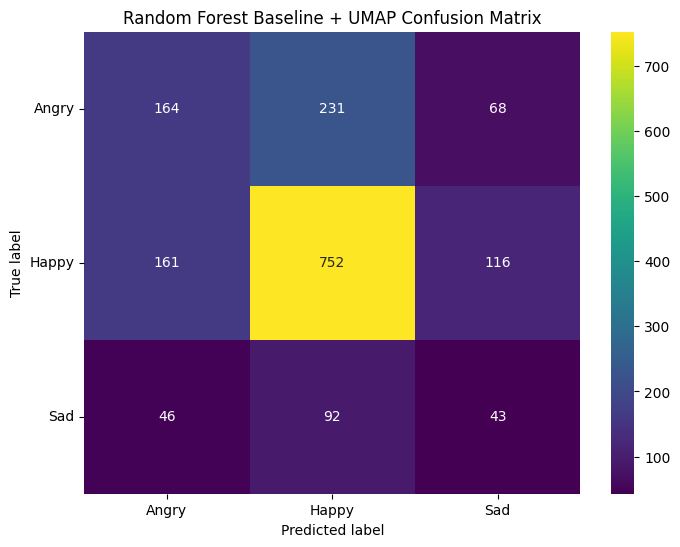

In [99]:
# use seaborn and matplotlib to plot
import seaborn as sns
import matplotlib.pyplot as plt

class_names = ['Angry', 'Happy', 'Sad']

plt.figure(figsize=(8,6))
cm = confusion_matrix(y_test, test_pred)
sns.heatmap(
cm,
annot=True,
fmt='d',
cmap='viridis',
xticklabels=class_names,
yticklabels=class_names
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.yticks(rotation=360)
plt.title("Random Forest Baseline + UMAP Confusion Matrix")
#plt.savefig("Conf_Matrix_Eigen_v1.png")
plt.show()

# Version 1 Final Notes:
## UMAP is good for plotting scatter
## Random Forest trains better on Eigen PCA than Eigen PCA > UMAP transformation
* ### This version runs the slowest but classifies better than version 2 or 3
* ### This could be due to:
  * ### Happy being left alone and not augmented
  * ### Only Angry + Sad were augmented
  * ### each class count = 4673